In [ ]:
install.packages("tidyverse")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(tidyverse)

Warning message in system("timedatectl", intern = TRUE):
“running command 'timedatectl' had status 1”
── Attaching packages ─────────────────────────────────────── tidyverse 1.3.2 ──
✔ ggplot2 3.4.0      ✔ purrr   0.3.5 
✔ tibble  3.1.8      ✔ dplyr   1.0.10
✔ tidyr   1.2.1      ✔ stringr 1.4.1 
✔ readr   2.1.3      ✔ forcats 0.5.2 
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()


# Hoofdstuk 12 - Tidy Data with tidyr
We gaan ' untidy'  data ' tidy' maken met behulp van de eerder geleerde technieken en enkele nieuwe:<br>
- Gathering of pivot_longer<br>
- Spreading of pivot_wider<br>
- Separate<br>
- Unite<br>

We gebruiken een [dataset van de World Health Organization met aantallen TBC-gevallen per land](https://github.com/GTB-TME/gtbreport2022) als voorbeeld.<br>

Bij ' tidy data':<br>
- is iedere kolom een variabele<br>
- is iedere rij een (unieke) observatie<br>
- is iedere cel gevuld<br>

Voor meer informatie over wat ' tidy data' is: https://www.jstatsoft.org/article/view/v059i10



# Gathering
Als je een dataset hebt waarbij sommige kolomnamen eigenlijk 'waarden' zijn in plaats van ' variabelen', kun je dat aanpassen met behulp van ' gathering':

In [ ]:
table4a

,country,1999,2000
,<chr>,<int>,<int>
1,Afghanistan,745,2666
2,Brazil,37737,80488
3,China,212258,213766


We gaan de jaartallen in kolom 2 en 3 vervangen door de variabelen ' jaar'  en 'cases':

In [ ]:
table4a %>%
  gather('1999','2000',key="year", value="cases")

country,year,cases
<chr>,<chr>,<int>
Afghanistan,1999,745
Brazil,1999,37737
China,1999,212258
Afghanistan,2000,2666
Brazil,2000,80488
China,2000,213766


Het kan ook met het 'pivot_longer'-commando:

In [ ]:
table4a %>%
  pivot_longer(c(`1999`, `2000`), names_to = "year", values_to = "cases")

country,year,cases
<chr>,<chr>,<int>
Afghanistan,1999,745
Afghanistan,2000,2666
Brazil,1999,37737
Brazil,2000,80488
China,1999,212258
China,2000,213766


# Spreading
Je gebruikt ' spreading' als er in 1 kolom 2 (of meer) variabelen staan:

In [ ]:
table2

country,year,type,count
<chr>,<int>,<chr>,<int>
Afghanistan,1999,cases,745
Afghanistan,1999,population,19987071
Afghanistan,2000,cases,2666
Afghanistan,2000,population,20595360
Brazil,1999,cases,37737
Brazil,1999,population,172006362
Brazil,2000,cases,80488
Brazil,2000,population,174504898
China,1999,cases,212258


In de kolom 'type' staan de variabelen 'cases'  en 'population'. Die willen we in 2 aparte kolommen hebben:

In [ ]:
spread(table2,key=type, value=count)

country,year,cases,population
<chr>,<int>,<int>,<int>
Afghanistan,1999,745,19987071
Afghanistan,2000,2666,20595360
Brazil,1999,37737,172006362
Brazil,2000,80488,174504898
China,1999,212258,1272915272
China,2000,213766,1280428583


Dit kan ook met het commando 'pivot_wider':

In [ ]:
table2 %>%
    pivot_wider(names_from = type, values_from = count)

country,year,cases,population
<chr>,<int>,<int>,<int>
Afghanistan,1999,745,19987071
Afghanistan,2000,2666,20595360
Brazil,1999,37737,172006362
Brazil,2000,80488,174504898
China,1999,212258,1272915272
China,2000,213766,1280428583


# Separate
Je kunt, als er in de vorm van een berekening meerdere variabelen in 1 kolom staan, ook het commando 'separate' gebruiken.

In [ ]:
table3

,country,year,rate
,<chr>,<int>,<chr>
1,Afghanistan,1999,745/19987071
2,Afghanistan,2000,2666/20595360
3,Brazil,1999,37737/172006362
4,Brazil,2000,80488/174504898
5,China,1999,212258/1272915272
6,China,2000,213766/1280428583


De kolom 'rate' is berekend door 'cases' te delen door 'population'. Met 'separate' halen we deze 2 variabelen uit elkaar:

In [ ]:
table3 %>%
  separate(rate, into = c("cases", "population"), sep="/")

country,year,cases,population
<chr>,<int>,<chr>,<chr>
Afghanistan,1999,745,19987071
Afghanistan,2000,2666,20595360
Brazil,1999,37737,172006362
Brazil,2000,80488,174504898
China,1999,212258,1272915272
China,2000,213766,1280428583


Keurig gesplitst, maar eigenlijk zijn ' cases' en 'population' geen characters maar numbers. Dat kunnen we ook aanpassen:

In [ ]:
table3 %>%
  separate(rate, into = c("cases", "population"), sep="/", convert=TRUE)

country,year,cases,population
<chr>,<int>,<int>,<int>
Afghanistan,1999,745,19987071
Afghanistan,2000,2666,20595360
Brazil,1999,37737,172006362
Brazil,2000,80488,174504898
China,1999,212258,1272915272
China,2000,213766,1280428583


# Unite
Met 'unite' voegen we meerdere kolommen samen in 1 kolom. Als voorbeeld splitsen we eerst de jaar-kolom uit tabel 3 in 2 kolommen:

In [ ]:
table3 %>%
  separate(year, into = c("century", "year"), sep = 2)

country,century,year,rate
<chr>,<chr>,<chr>,<chr>
Afghanistan,19,99,745/19987071
Afghanistan,20,00,2666/20595360
Brazil,19,99,37737/172006362
Brazil,20,00,80488/174504898
China,19,99,212258/1272915272
China,20,00,213766/1280428583


Niet echt handig, deze splitsing, dus gebruiken we 'unite' om beide kolommen weer samen te voegen:

In [ ]:
table5 %>%
  unite(new, century, year)

country,new,rate
<chr>,<chr>,<chr>
Afghanistan,19_99,745/19987071
Afghanistan,20_00,2666/20595360
Brazil,19_99,37737/172006362
Brazil,20_00,80488/174504898
China,19_99,212258/1272915272
China,20_00,213766/1280428583


Ziet er nog lelijk uit, dus halen we het streepje weg:

In [ ]:
table5 %>%
  unite(new, century, year, sep = "")

country,new,rate
<chr>,<chr>,<chr>
Afghanistan,1999,745/19987071
Afghanistan,2000,2666/20595360
Brazil,1999,37737/172006362
Brazil,2000,80488/174504898
China,1999,212258/1272915272
China,2000,213766/1280428583


# Missing Values
We hebben al eerder gezien dat ontbrekende waarden vervelend zijn, bijvoorbeeld als je wilt gaan rekenen met de data. Je zult daarom moeten bedenken wat je met ontbrekende (NA) data doet:<br>
- rijen met NA's verwijderen: na.omit() of na.rm = TRUE<br>
- NA's aanvullen met eerdere waarden: fill()

# Case Study: Tidy the [WHO Global Tuberculosis Report 2014](https://www.who.int/teams/global-tuberculosis-programme/tb-reports/global-tuberculosis-report-2022)
Laten we eens kijken hoe de data er, ongeschoond, uitziet:

In [ ]:
who

country,iso2,iso3,year,new_sp_m014,new_sp_m1524,new_sp_m2534,new_sp_m3544,new_sp_m4554,new_sp_m5564,⋯,newrel_m4554,newrel_m5564,newrel_m65,newrel_f014,newrel_f1524,newrel_f2534,newrel_f3544,newrel_f4554,newrel_f5564,newrel_f65
<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
Afghanistan,AF,AFG,1980,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Afghanistan,AF,AFG,1981,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Afghanistan,AF,AFG,1982,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Afghanistan,AF,AFG,1983,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Afghanistan,AF,AFG,1984,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Afghanistan,AF,AFG,1985,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Afghanistan,AF,AFG,1986,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Afghanistan,AF,AFG,1987,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
Afghanistan,AF,AFG,1988,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA


Een typisch voorbeeld: vreemde kolomnamnen, wellicht overbodige kolommen, ontbrekende waarden .. een puinhoop dus.

Laten we eens kijken of we deze dataset wat kunnen aanpassen:<br>
- land, iso2 en iso3 lijken alle drie hetzelfde aan te geven<br>
- de kolom 'year' is een variabele, kunnen we zo laten<br>
- wat er precies in de 56 andere kolommen staat, weten we niet, het lijken wel ' waarden' te zijn.<br>

We kunnen met 'gather' en/of 'pivot_long' het aantal kolommen wat beperken:

In [ ]:
who1 <- who %>%
  pivot_longer(
    cols = new_sp_m014:newrel_f65,
    names_to = "key",
    values_to = "cases",
    values_drop_na = TRUE
  )

We geven de nieuwe kolom (voorlopig) de naam 'key' en verwijderen en passant ook alle NA's:

In [ ]:
who1

country,iso2,iso3,year,key,cases
<chr>,<chr>,<chr>,<int>,<chr>,<int>
Afghanistan,AF,AFG,1997,new_sp_m014,0
Afghanistan,AF,AFG,1997,new_sp_m1524,10
Afghanistan,AF,AFG,1997,new_sp_m2534,6
Afghanistan,AF,AFG,1997,new_sp_m3544,3
Afghanistan,AF,AFG,1997,new_sp_m4554,5
Afghanistan,AF,AFG,1997,new_sp_m5564,2
Afghanistan,AF,AFG,1997,new_sp_m65,0
Afghanistan,AF,AFG,1997,new_sp_f014,5
Afghanistan,AF,AFG,1997,new_sp_f1524,38


We gaan van 60 naar 6 kolommen, dat is alvast overzichtelijker. Wel hebben we nu flink meer rijen: van 7.240 naar 76.046.

Wat betekenen nu de namen in de kolom 'key'?

In [ ]:
?who

The data uses the original codes given by the World Health
     Organization. The column names for columns five through 60 are
     made by combining ‘new_’ to a code for method of diagnosis (‘rel’
     = relapse, ‘sn’ = negative pulmonary smear, ‘sp’ = positive
     pulmonary smear, ‘ep’ = extrapulmonary) to a code for gender (‘f’
     = female, ‘m’ = male) to a code for age group (‘014’ = 0-14 yrs of
     age, ‘1524’ = 15-24 years of age, ‘2534’ = 25 to 34 years of age,
     ‘3544’ = 35 to 44 years of age, ‘4554’ = 45 to 54 years of age,
     ‘5564’ = 55 to 64 years of age, ‘65’ = 65 years of age or older).

Helaas zijn niet alle namen in de kolom 'key' volgens bovenstaande omschrijving:<br>
in plaats van new_rel zien we ook newrel.

We gaan dit oplossen met een str_replace() commando:

In [ ]:
who2 <- who1 %>%
  mutate(key = stringr::str_replace(key, "newrel", "new_rel"))
who2

country,iso2,iso3,year,key,cases
<chr>,<chr>,<chr>,<int>,<chr>,<int>
Afghanistan,AF,AFG,1997,new_sp_m014,0
Afghanistan,AF,AFG,1997,new_sp_m1524,10
Afghanistan,AF,AFG,1997,new_sp_m2534,6
Afghanistan,AF,AFG,1997,new_sp_m3544,3
Afghanistan,AF,AFG,1997,new_sp_m4554,5
Afghanistan,AF,AFG,1997,new_sp_m5564,2
Afghanistan,AF,AFG,1997,new_sp_m65,0
Afghanistan,AF,AFG,1997,new_sp_f014,5
Afghanistan,AF,AFG,1997,new_sp_f1524,38


We gaan nu de kolom 'key' splitsen, eerst op basis van de 'underscore'(_):

In [ ]:
who3 <- who2 %>%
  separate(key, c("new", "type", "sexage"), sep = "_")
who3

country,iso2,iso3,year,new,type,sexage,cases
<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>
Afghanistan,AF,AFG,1997,new,sp,m014,0
Afghanistan,AF,AFG,1997,new,sp,m1524,10
Afghanistan,AF,AFG,1997,new,sp,m2534,6
Afghanistan,AF,AFG,1997,new,sp,m3544,3
Afghanistan,AF,AFG,1997,new,sp,m4554,5
Afghanistan,AF,AFG,1997,new,sp,m5564,2
Afghanistan,AF,AFG,1997,new,sp,m65,0
Afghanistan,AF,AFG,1997,new,sp,f014,5
Afghanistan,AF,AFG,1997,new,sp,f1524,38


We gooien overbodige kolommen (iso2, iso3 en new) er uit:

In [ ]:
who4 <- who3 %>%
  select(-new, -iso2, -iso3)
who4

country,year,type,sexage,cases
<chr>,<int>,<chr>,<chr>,<int>
Afghanistan,1997,sp,m014,0
Afghanistan,1997,sp,m1524,10
Afghanistan,1997,sp,m2534,6
Afghanistan,1997,sp,m3544,3
Afghanistan,1997,sp,m4554,5
Afghanistan,1997,sp,m5564,2
Afghanistan,1997,sp,m65,0
Afghanistan,1997,sp,f014,5
Afghanistan,1997,sp,f1524,38


Nu hoeven we alleen nog de kolom 'sexage' te splisten in ' sex' en 'age':

In [ ]:
who5 <- who4 %>%
  separate(sexage, c("sex", "age"), sep = 1)
who5

country,year,type,sex,age,cases
<chr>,<int>,<chr>,<chr>,<chr>,<int>
Afghanistan,1997,sp,m,014,0
Afghanistan,1997,sp,m,1524,10
Afghanistan,1997,sp,m,2534,6
Afghanistan,1997,sp,m,3544,3
Afghanistan,1997,sp,m,4554,5
Afghanistan,1997,sp,m,5564,2
Afghanistan,1997,sp,m,65,0
Afghanistan,1997,sp,f,014,5
Afghanistan,1997,sp,f,1524,38


Et Voila: een 'tidy' dataset, waarmee we nu fijne analysen, modellen en/of grafieken zouden kunnen maken!

# De Huiskamervraag
Maak een (leesbare) grafiek per land met daarin een overzicht van de aantallen TBC, gesplitst in man en vrouw.

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


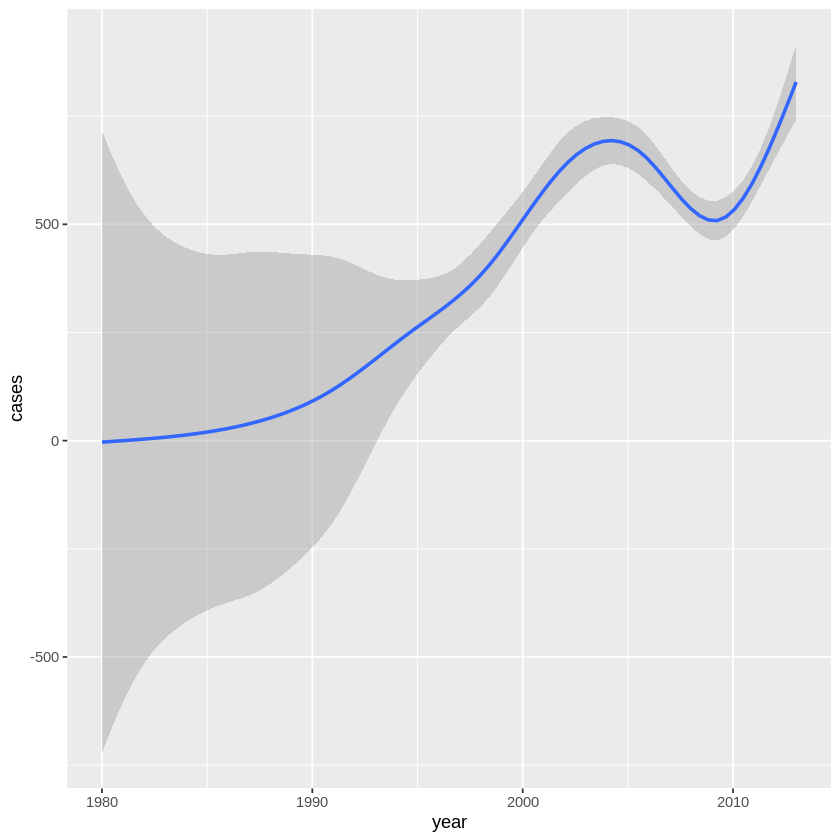

In [ ]:
ggplot(data = who5) +
  geom_smooth(mapping = aes(x = year , y = cases))

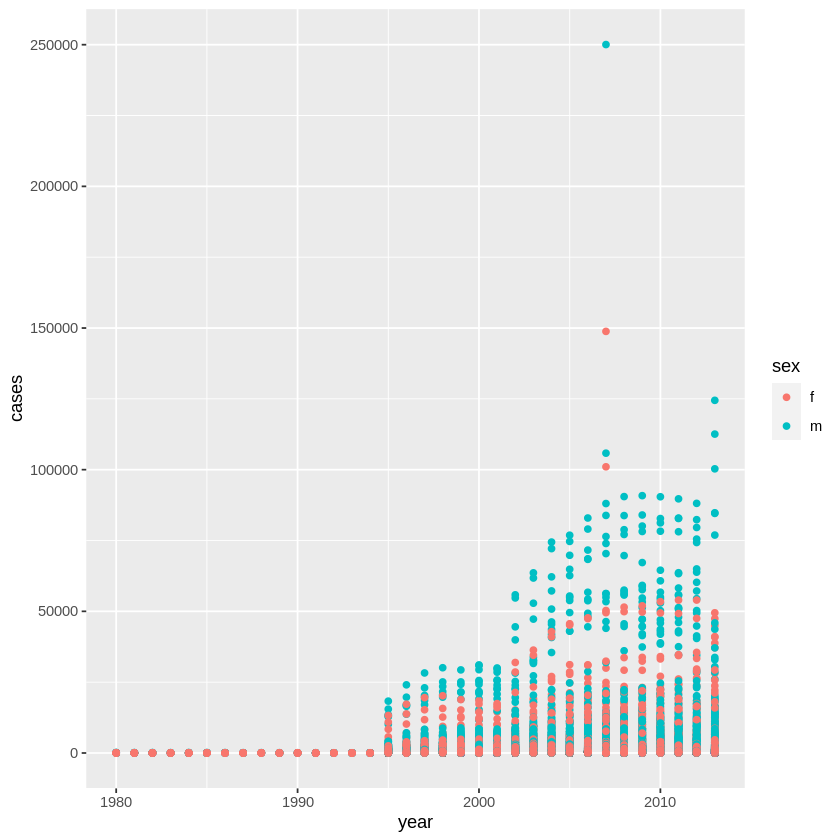

In [ ]:
ggplot(data = who5) +
  geom_point(mapping = aes(x = year , y = cases, color=sex))

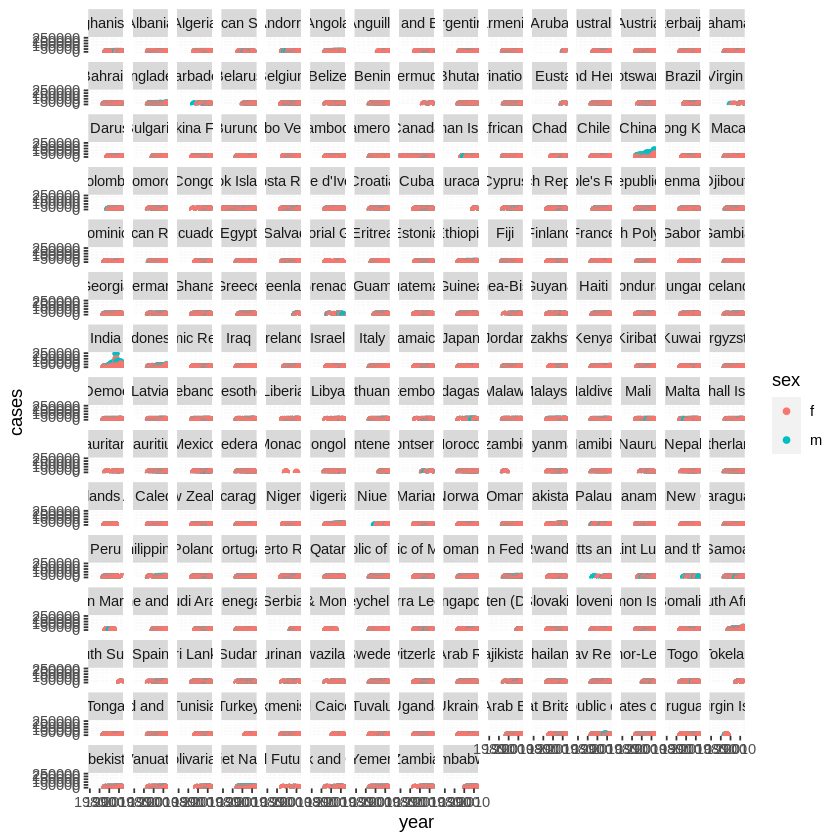

In [ ]:
ggplot(data = who5) +
  geom_point(mapping = aes(x = year , y = cases, color=sex)) +
  facet_wrap(~ country)

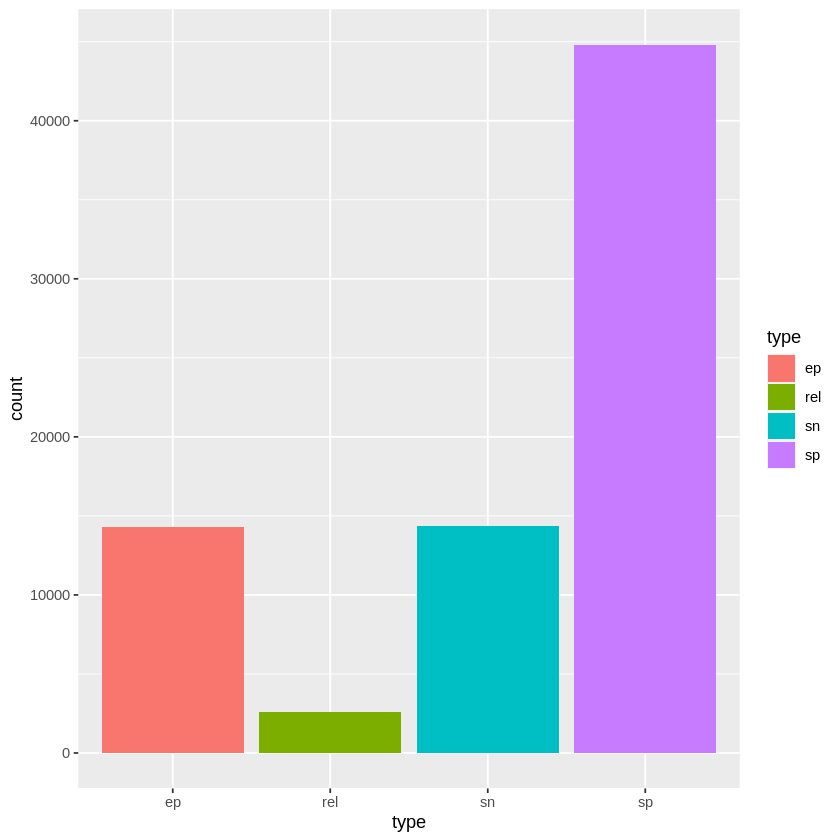

In [ ]:
ggplot(data = who5) +
  geom_bar(mapping = aes(x =type, fill=type))

Code for method of diagnosis:<br>
- ‘rel’ = relapse<br>
- ‘sn’ = negative pulmonary smear<br>
- ‘sp’ = positive pulmonary smear<br>
- ‘ep’ = extrapulmonary

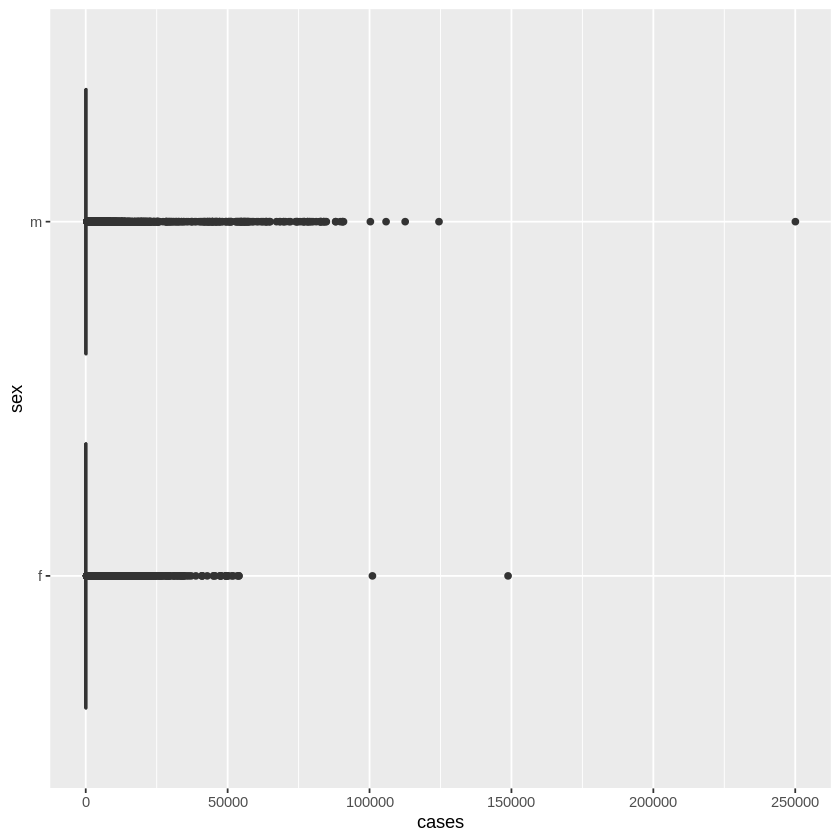

In [ ]:
ggplot(data = who5, mapping = aes(x = sex, y = cases)) +
  geom_boxplot()+
  coord_flip()

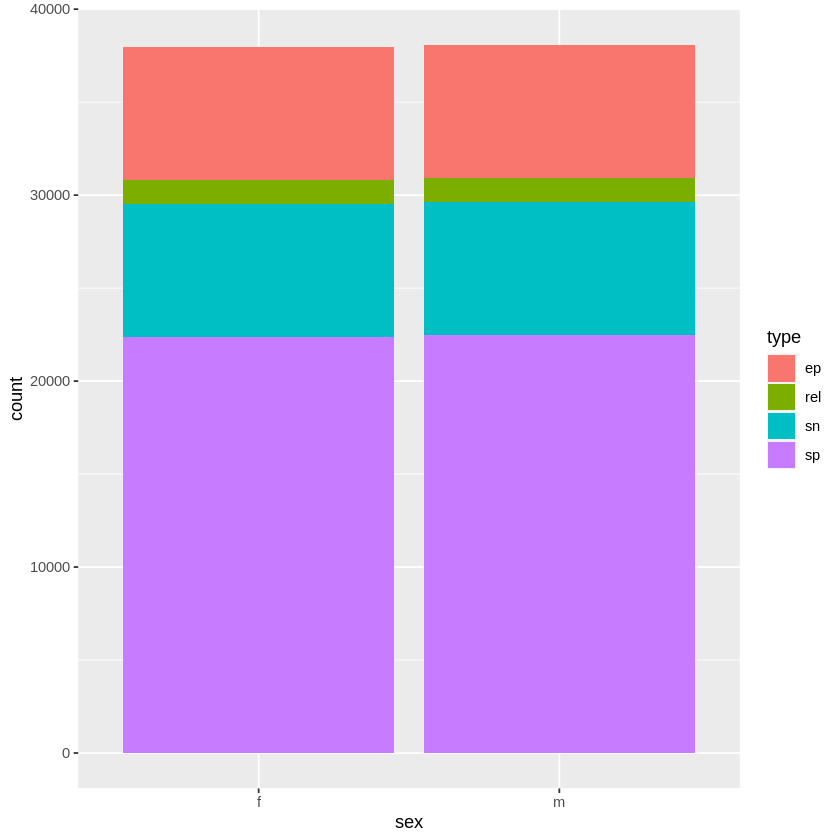

In [ ]:
ggplot(data = who5) +
  geom_bar(mapping = aes(x = sex, fill = type))

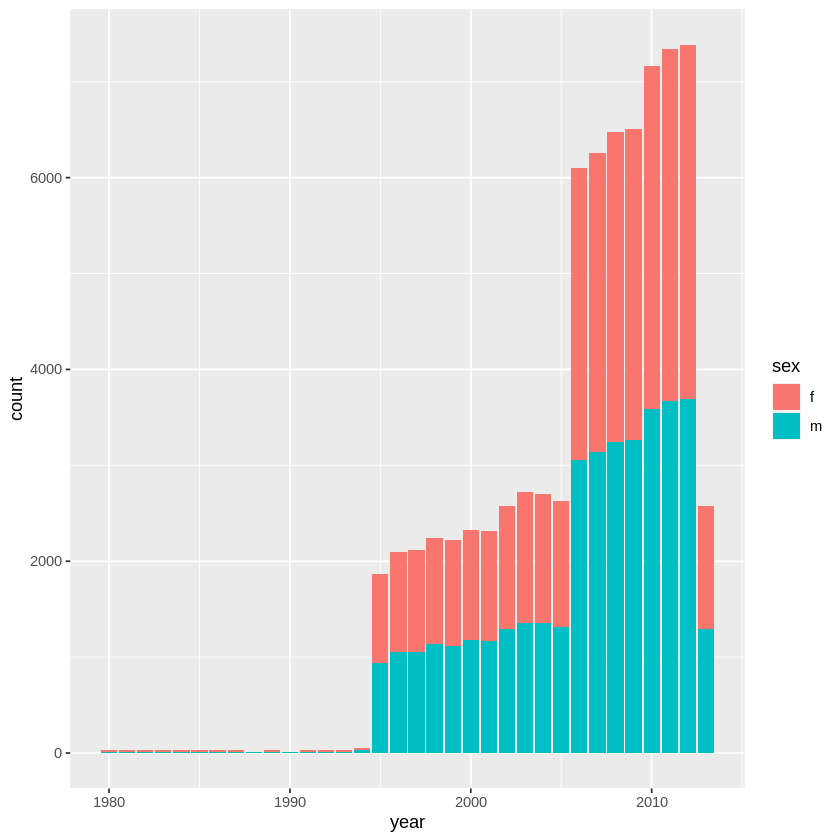

In [ ]:
ggplot(data = who5) +
  geom_bar(mapping = aes(x = year, fill = sex))